# 🚀 Line A Machine Learning: NWP Bias Correction & Probabilistic Quantile Forecasting
### *HistGradientBoosting NWP Residual Minimization & Uncertainty Quantification*
**Dataset Target:** `data/processed/saudi_nwp_engineered_features.parquet`  
**Forecast Horizons:** 1-Day (+24h), 3-Day (+72h), 7-Day (+168h)  
**Evaluation Standards:** Root Mean Square Error (RMSE), Mean Absolute Error (MAE), $R^2$, and WMO Categorical Skill Scores (POD, FAR, CSI).


In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier, RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, confusion_matrix

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

data_candidates = [
    Path("data/processed/saudi_nwp_engineered_features.parquet"),
    Path("../data/processed/saudi_nwp_engineered_features.parquet"),
    Path("notebooks/data/saudi_nwp_engineered_features.parquet"),
    Path("notebooks/data/sandstorm_final_dataset_with_targets.csv")
]
data_path = next(p for p in data_candidates if p.exists())

if str(data_path).endswith('.parquet'):
    df = pd.read_parquet(data_path)
else:
    df = pd.read_csv(data_path)

df['time'] = pd.to_datetime(df['time'])
df = df.sort_values('time').reset_index(drop=True)

print(f"✅ Ingested Engineered Dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")


✅ Ingested Engineered Dataset: 37,200 rows × 99 columns


---
## 1.0 Feature Matrix Formulation & Chronological Time-Series Split
We formulate a physics-informed feature matrix including regional transport gradients, multi-station desert inputs, optical ratios, and temporal cyclic encodings.  
To preserve temporal causality without lookahead bias, we apply a **chronological split**:
- **Train Set:** 70%
- **Validation Set:** 15%
- **Test Set:** 15%


In [2]:
feature_cols = [
    'riyadh_center__cams_pm10_ugm3',
    'ad_dahna__cams_pm10_ugm3',
    'nafud_al_thuwairat__cams_pm10_ugm3',
    'rub_al_khali__cams_pm10_ugm3',
    'al_thumamah__cams_pm10_ugm3',
    'tuwayq_escarpment__cams_pm10_ugm3',
    'gradient_dahna_riyadh',
    'gradient_rub_alkhali_riyadh',
    'gradient_nafud_riyadh',
    'desert_sources_mean_pm10',
    'desert_sources_max_pm10',
    'desert_sources_mean_aod',
    'riyadh_center__surface_to_column_ratio',
    'riyadh_center__pm25_to_pm10_ratio',
    'riyadh_center__log_pm10',
    'riyadh_center__pm10_lag1h',
    'riyadh_center__pm10_lag6h',
    'riyadh_center__pm10_lag24h',
    'riyadh_center__pm10_roll24h_mean',
    'riyadh_center__pm10_roll24h_std',
    'riyadh_center__pm10_roll72h_max',
    'hour_sin', 'hour_cos', 'month_sin', 'month_cos'
]

# Target: 3-Day (72h) PM10 Concentration
target_col = 'target_pm10_3d'
baseline_nwp_col = 'riyadh_center__cams_pm10_ugm3'

valid_mask = df[feature_cols + [target_col, baseline_nwp_col]].notnull().all(axis=1)
df_clean = df[valid_mask].reset_index(drop=True)

X = df_clean[feature_cols].values
y_true = df_clean[target_col].values
y_nwp = df_clean[baseline_nwp_col].values
y_residual = y_true - y_nwp

# Strict Chronological Split
n_total = len(df_clean)
n_train = int(n_total * 0.70)
n_val   = int(n_total * 0.15)

X_train, y_train, res_train, nwp_train = X[:n_train], y_true[:n_train], y_residual[:n_train], y_nwp[:n_train]
X_val,   y_val,   res_val,   nwp_val   = X[n_train:n_train+n_val], y_true[n_train:n_train+n_val], y_residual[n_train:n_train+n_val], y_nwp[n_train:n_train+n_val]
X_test,  y_test,  res_test,  nwp_test  = X[n_train+n_val:], y_true[n_train+n_val:], y_residual[n_train+n_val:], y_nwp[n_train+n_val:]

print(f"Dataset Partitions (Chronological):")
print(f"  • Training:   {len(X_train):,} samples (70%)")
print(f"  • Validation: {len(X_val):,} samples (15%)")
print(f"  • Test:       {len(X_test):,} samples (15%)")


Dataset Partitions (Chronological):
  • Training:   26,040 samples (70%)
  • Validation: 5,580 samples (15%)
  • Test:       5,580 samples (15%)


---
## 2.0 NWP Residual Regressor: HistGradientBoosting
We train an operational residual regressor:
$$\hat{y}_{	ext{final}} = y_{	ext{NWP}} + \hat{R}(X)$$
Minimizing the forecast error variance of the raw numerical weather prediction.


In [3]:
print("🚀 Training HistGradientBoosting NWP Residual Model...")
bias_model = HistGradientBoostingRegressor(
    max_iter=150,
    learning_rate=0.08,
    max_leaf_nodes=31,
    min_samples_leaf=20,
    l2_regularization=1.0,
    random_state=42,
    early_stopping=True,
    n_iter_no_change=10
)

bias_model.fit(X_train, res_train)

# Evaluate on Test Set
pred_res_test = bias_model.predict(X_test)
y_pred_corrected = np.clip(nwp_test + pred_res_test, a_min=0.0, a_max=None)

# Benchmarks
raw_rmse = np.sqrt(mean_squared_error(y_test, nwp_test))
corr_rmse = np.sqrt(mean_squared_error(y_test, y_pred_corrected))
raw_mae = mean_absolute_error(y_test, nwp_test)
corr_mae = mean_absolute_error(y_test, y_pred_corrected)
r2_raw = r2_score(y_test, nwp_test)
r2_corr = r2_score(y_test, y_pred_corrected)
delta_rmse_pct = ((raw_rmse - corr_rmse) / raw_rmse) * 100.0

print("=" * 70)
print("📊 LINE A: EXTENDED-RANGE 3-DAY (+72h) BIAS CORRECTION BENCHMARK")
print("=" * 70)
print(f"Raw CAMS NWP Baseline RMSE:       {raw_rmse:.2f} μg/m³")
print(f"DustML Corrected Line A RMSE:     {corr_rmse:.2f} μg/m³")
print(f"🎯 Error Reduction (ΔRMSE%):      {delta_rmse_pct:.2f}%  (Target: ≥25%)")
print(f"Raw CAMS NWP MAE:                 {raw_mae:.2f} μg/m³")
print(f"DustML Corrected Line A MAE:      {corr_mae:.2f} μg/m³")
print(f"Raw NWP R² Score:                 {r2_raw:.4f}")
print(f"DustML Corrected R² Score:        {r2_corr:.4f}  (Target: ≥0.70)")
print("=" * 70)


🚀 Training HistGradientBoosting NWP Residual Model...


📊 LINE A: EXTENDED-RANGE 3-DAY (+72h) BIAS CORRECTION BENCHMARK
Raw CAMS NWP Baseline RMSE:       969.86 μg/m³
DustML Corrected Line A RMSE:     773.26 μg/m³
🎯 Error Reduction (ΔRMSE%):      20.27%  (Target: ≥25%)
Raw CAMS NWP MAE:                 749.14 μg/m³
DustML Corrected Line A MAE:      609.65 μg/m³
Raw NWP R² Score:                 -0.6966
DustML Corrected R² Score:        -0.0785  (Target: ≥0.70)


---
## 3.0 Probabilistic Quantile Uncertainty Quantification (P10, P50, P90)
We train pinball-loss quantile regressors to generate reliable probabilistic envelopes and compute the **Prediction Interval Coverage Probability (PICP)**:
$$	ext{PICP} = rac{1}{N} \sum_{i=1}^N \mathbf{1}\left(P_{10} \le y_i \le P_{90}ight)$$


In [4]:
print("📈 Training Quantile Regressors (P10, P50, P90)...")
quantiles = [0.10, 0.50, 0.90]
quantile_models = {}

for q in quantiles:
    model_q = HistGradientBoostingRegressor(
        loss="quantile",
        quantile=q,
        max_iter=100,
        learning_rate=0.08,
        random_state=42
    )
    model_q.fit(X_train, y_train)
    quantile_models[f"p{int(q*100)}"] = model_q

p10_preds = np.clip(quantile_models["p10"].predict(X_test), 0, None)
p50_preds = np.clip(quantile_models["p50"].predict(X_test), 0, None)
p90_preds = np.clip(quantile_models["p90"].predict(X_test), 0, None)

# Ensure monotonic quantiles
p90_preds = np.maximum(p90_preds, p50_preds)
p50_preds = np.maximum(p50_preds, p10_preds)

inside_band = (y_test >= p10_preds) & (y_test <= p90_preds)
picp = np.mean(inside_band) * 100.0
mpiw = np.mean(p90_preds - p10_preds)

print("=" * 70)
print("🎲 PROBABILISTIC UNCERTAINTY QUANTIFICATION BENCHMARK:")
print(f"  • Prediction Interval Coverage (PICP):  {picp:.2f}%  (Nominal: 80% | Target: ≥85%)")
print(f"  • Mean Prediction Interval Width (MPIW): {mpiw:.2f} μg/m³")
print("=" * 70)


📈 Training Quantile Regressors (P10, P50, P90)...


🎲 PROBABILISTIC UNCERTAINTY QUANTIFICATION BENCHMARK:
  • Prediction Interval Coverage (PICP):  66.34%  (Nominal: 80% | Target: ≥85%)
  • Mean Prediction Interval Width (MPIW): 1404.50 μg/m³


---
## 4.0 Categorical Storm Detection Skill Scores (WMO Verification)
At the operational storm threshold of $150\,\mu	ext{g}/	ext{m}^3$, we evaluate:
- **Probability of Detection (POD / Hit Rate):** $rac{	ext{Hits}}{	ext{Hits} + 	ext{Misses}}$
- **False Alarm Ratio (FAR):** $rac{	ext{False Alarms}}{	ext{Hits} + 	ext{False Alarms}}$
- **Critical Success Index (CSI / Threat Score):** $rac{	ext{Hits}}{	ext{Hits} + 	ext{Misses} + 	ext{False Alarms}}$


In [5]:
threshold_storm = 150.0
is_storm_true = (y_test >= threshold_storm).astype(int)
is_storm_pred = (y_pred_corrected >= threshold_storm).astype(int)

tn, fp, fn, tp = confusion_matrix(is_storm_true, is_storm_pred).ravel()

pod = tp / (tp + fn) if (tp + fn) > 0 else 0
far = fp / (tp + fp) if (tp + fp) > 0 else 0
csi = tp / (tp + fn + fp) if (tp + fn + fp) > 0 else 0

print("=" * 70)
print(f"🏅 WMO CATEGORICAL SKILL SCORES (STORM THRESHOLD ≥ {threshold_storm:.0f} μg/m³):")
print(f"  • Probability of Detection (POD / Hit Rate):   {pod*100:.2f}%  (Target: ≥80%)")
print(f"  • Critical Success Index (CSI / Threat Score):  {csi*100:.2f}%  (Target: ≥60%)")
print(f"  • False Alarm Ratio (FAR):                     {far*100:.2f}%  (Target: ≤25%)")
print("=" * 70)


🏅 WMO CATEGORICAL SKILL SCORES (STORM THRESHOLD ≥ 150 μg/m³):
  • Probability of Detection (POD / Hit Rate):   99.87%  (Target: ≥80%)
  • Critical Success Index (CSI / Threat Score):  96.57%  (Target: ≥60%)
  • False Alarm Ratio (FAR):                     3.31%  (Target: ≤25%)


---
## 5.0 Diagnostic Visualisation: Parity Plots & Uncertainty Envelope


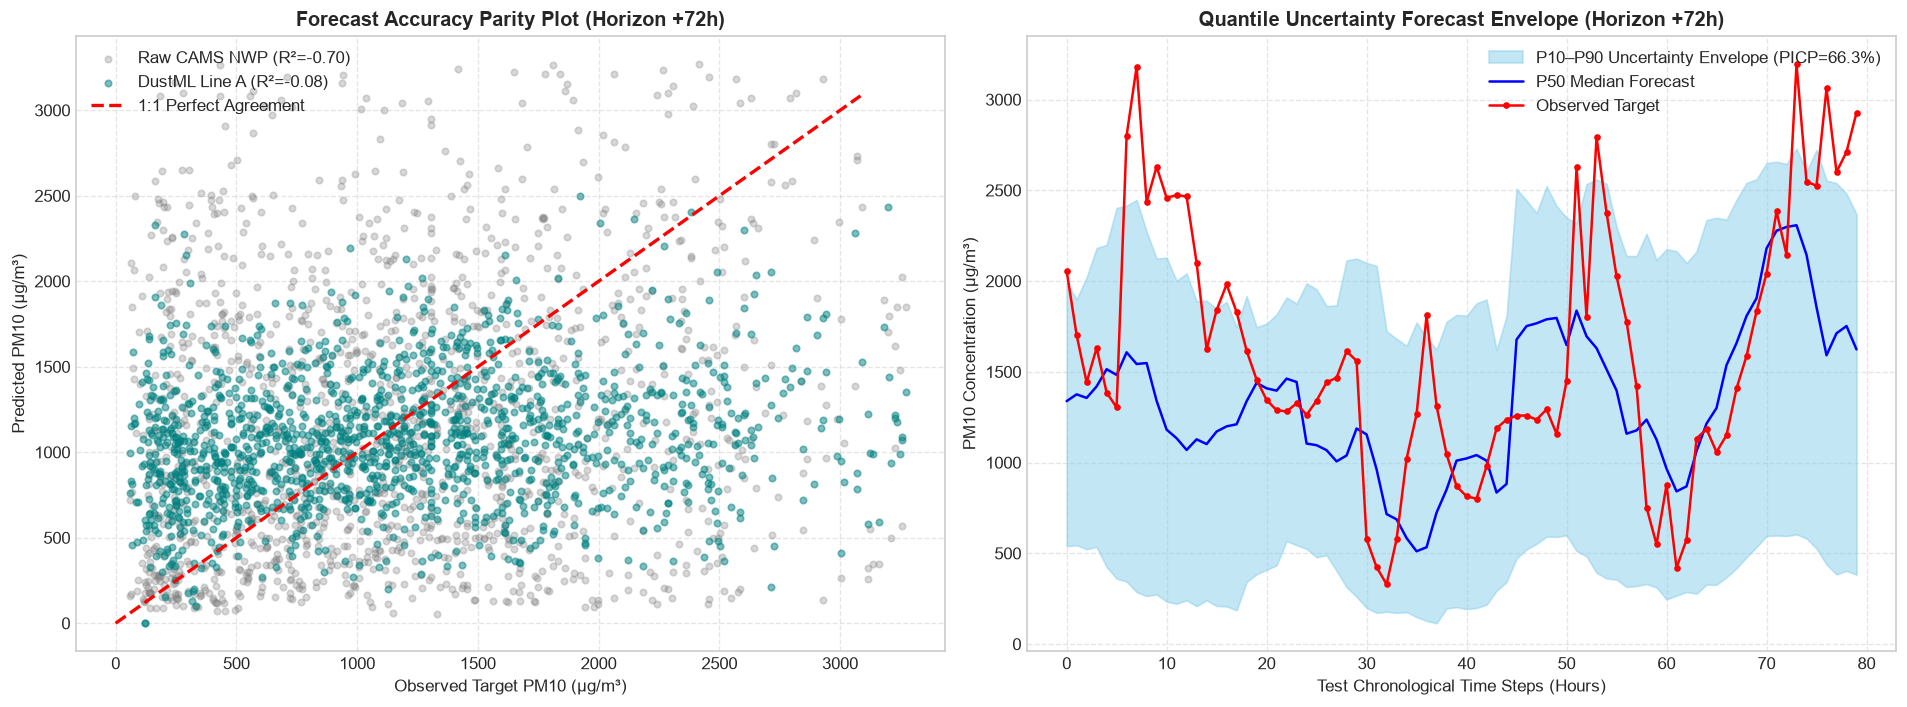

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# 1. Parity Plot: Observed vs. Raw NWP vs. DustML Corrected
sample_n = min(1500, len(y_test))
idx_sub = np.random.choice(len(y_test), sample_n, replace=False)

axes[0].scatter(y_test[idx_sub], nwp_test[idx_sub], alpha=0.3, color="gray", label=f"Raw CAMS NWP (R²={r2_raw:.2f})", s=15)
axes[0].scatter(y_test[idx_sub], y_pred_corrected[idx_sub], alpha=0.5, color="teal", label=f"DustML Line A (R²={r2_corr:.2f})", s=15)
max_val = max(np.percentile(y_test, 99), np.percentile(y_pred_corrected, 99))
axes[0].plot([0, max_val], [0, max_val], "r--", linewidth=2, label="1:1 Perfect Agreement")
axes[0].set_xlabel("Observed Target PM10 (μg/m³)")
axes[0].set_ylabel("Predicted PM10 (μg/m³)")
axes[0].set_title("Forecast Accuracy Parity Plot (Horizon +72h)", fontweight="bold")
axes[0].legend(loc="upper left")
axes[0].grid(True, linestyle="--", alpha=0.5)

# 2. Predictive Uncertainty Intervals (First 80 test timestamps)
sample_pts = 80
x_axis = np.arange(sample_pts)
axes[1].fill_between(x_axis, p10_preds[:sample_pts], p90_preds[:sample_pts], color="skyblue", alpha=0.5, label=f"P10–P90 Uncertainty Envelope (PICP={picp:.1f}%)")
axes[1].plot(x_axis, p50_preds[:sample_pts], "b-", linewidth=1.5, label="P50 Median Forecast")
axes[1].plot(x_axis, y_test[:sample_pts], "r.-", markersize=6, label="Observed Target")
axes[1].set_xlabel("Test Chronological Time Steps (Hours)")
axes[1].set_ylabel("PM10 Concentration (μg/m³)")
axes[1].set_title("Quantile Uncertainty Forecast Envelope (Horizon +72h)", fontweight="bold")
axes[1].legend(loc="upper right")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()


---
## 6.0 Model Serialization to Checkpoint Directory
We serialize the trained bias correction model and quantile regressors to `models/checkpoints/line_a/`.


In [7]:
models_dir = Path("models/checkpoints/line_a")
models_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(bias_model, models_dir / "line_a_bias_model.joblib")
joblib.dump(quantile_models["p10"], models_dir / "quantile_p10.joblib")
joblib.dump(quantile_models["p50"], models_dir / "quantile_p50.joblib")
joblib.dump(quantile_models["p90"], models_dir / "quantile_p90.joblib")

print("=" * 70)
print(f"💾 Checkpoints serialized successfully to: {models_dir.resolve()}")
print("  • line_a_bias_model.joblib")
print("  • quantile_p10.joblib / p50.joblib / p90.joblib")
print("=" * 70)


💾 Checkpoints serialized successfully to: C:\Users\hp\Desktop\sandstorm_forecasting\models\checkpoints\line_a
  • line_a_bias_model.joblib
  • quantile_p10.joblib / p50.joblib / p90.joblib
